### Generating a Synthetic Dataset

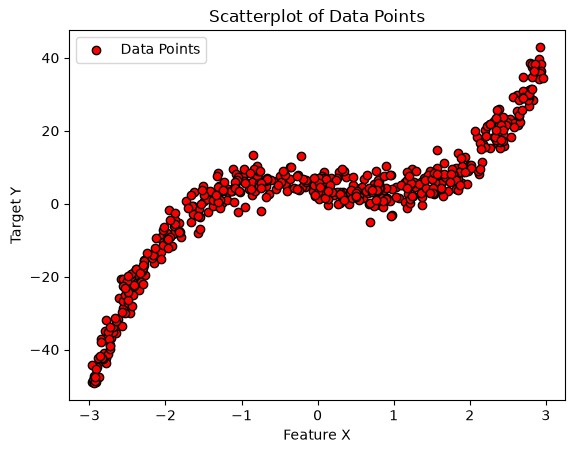

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

np.random.seed(42)

x = np.random.uniform(-3, 3, 500)

noise = np.random.normal(0, 3, 500)
y = (2 * (x**3)) - (x**2) - (3 * x) + 5 + noise

df = pd.DataFrame({'Feature_X': x   , 'Target_Y': y})

# 5. Split into Train and Test sets just like a real project
X_train, X_test, y_train, y_test = train_test_split(
    df[['Feature_X']], df['Target_Y'], test_size=0.2, random_state=42
)

#Plot a Scatterplot of the data
plt.scatter(x , y, color='red', label='Data Points', edgecolors='k')
plt.xlabel('Feature X')
plt.ylabel('Target Y')
plt.title('Scatterplot of Data Points')
plt.legend()
plt.show()

##### Training a LR Model on the Synthetic Data

In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.7195721563338623


##### Training the LR Model after Polynomial Transformation

In [63]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_features = PolynomialFeatures(degree=5 , include_bias=True)

x_train_poly = polynomial_features.fit_transform(X_train)
x_test_poly = polynomial_features.transform(X_test)


In [64]:
lr_poly = LinearRegression()
lr_poly.fit(x_train_poly, y_train)
y_pred_poly = lr_poly.predict(x_test_poly)

print("R2 Score (Polynomial Regression):", r2_score(y_test, y_pred_poly))

R2 Score (Polynomial Regression): 0.9710542558349826


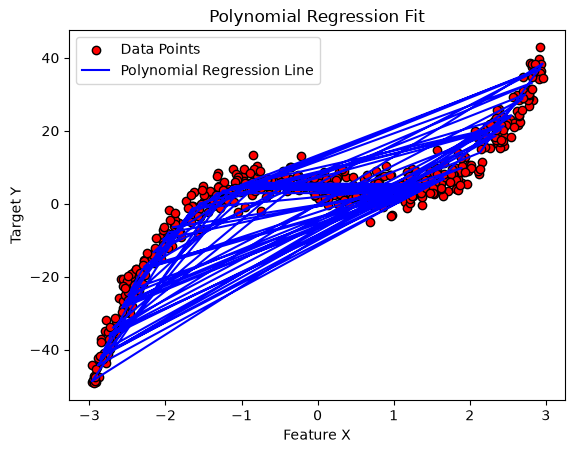

In [66]:
#Plot a line on the Graph to show the prediction of the model
plt.scatter(x , y, color='red', label='Data Points', edgecolors='k')
plt.plot(X_test, y_pred_poly, color='blue', label='Polynomial Regression Line')
plt.xlabel('Feature X')
plt.ylabel('Target Y')
plt.title('Polynomial Regression Fit')
plt.legend()
plt.show()

## For 3D Data

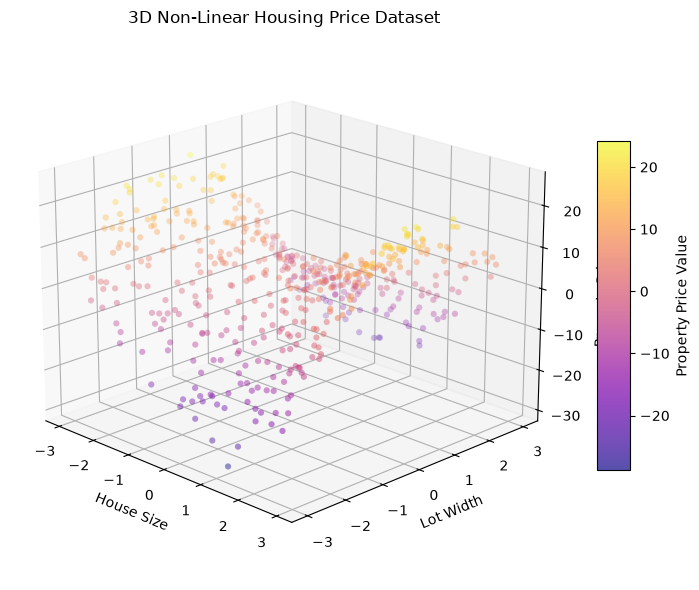

In [70]:
# 1. Generate Synthetic Data
np.random.seed(42)
house_size = np.random.uniform(-3, 3, 500)
lot_width = np.random.uniform(-3, 3, 500)

# Non-linear relationship with noise
true_price_curve = (2 * (house_size**2)) - (3 * (lot_width**2)) + (house_size * lot_width) + 4
price_noise = np.random.normal(0, 2, 500)
property_price = true_price_curve + price_noise

# Build DataFrame and Split
housing_df = pd.DataFrame({
    'house_size': house_size, 
    'lot_width': lot_width, 
    'property_price': property_price
})

features = housing_df[['house_size', 'lot_width']]
target = housing_df['property_price']

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42
)

# Plot 3D Visualisation
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

scatter_plot = ax.scatter(
    house_size, lot_width, property_price, 
    c=property_price, cmap='plasma', alpha=0.7, edgecolors='none'
)

ax.set_xlabel('House Size')
ax.set_ylabel('Lot Width')
ax.set_zlabel('Property Price')
ax.set_title('3D Non-Linear Housing Price Dataset')
fig.colorbar(scatter_plot, ax=ax, label='Property Price Value', shrink=0.6, aspect=10)

ax.view_init(elev=20, azim=-45)
plt.tight_layout()
plt.show()


#### Linear Regression on 3D data

In [72]:
from sklearn.linear_model import LinearRegression

lr3D = LinearRegression()
lr3D.fit(X_train, y_train)
y_pred_3D = lr3D.predict(X_test)

print(r2_score(y_test, y_pred_3D))

-0.004521282276155114


#### Polynomial Regressor on 3D data

In [75]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_features = PolynomialFeatures(degree=2 , include_bias=True)

x_train_poly = polynomial_features.fit_transform(X_train)
x_test_poly = polynomial_features.transform(X_test)

lr_poly = LinearRegression()
lr_poly.fit(x_train_poly, y_train)
y_pred_poly = lr_poly.predict(x_test_poly)

print("R2 Score (Polynomial Regression):", r2_score(y_test, y_pred_poly))

R2 Score (Polynomial Regression): 0.9618069599508183
